# Interactive Pipeline — Paper Analyzer (PDF and/or LaTeX)

A **fully self-contained** notebook: you can download just this file (without the rest of the repository) and run it. It doesn't depend on `main.py`, on `src/`, or on any pre-downloaded paper: **it fetches a real paper from INSPIRE HEP on its own, as PDF, LaTeX source, or both**, runs the full pipeline on the chosen source(s) and, when both are selected, compares the two results.

**How to use it interactively:** in Section 12, uncomment the fields of `QUERY_FIELDS` you want in the INSPIRE query (title, author, date, journal, citations, ...) and set `TYPE` to `"both"`, `"pdf"` or `"latex"`.

**LLM provider: OpenRouter only** (free-tier model `openrouter/free`), for both text and vision. No calls to Gemini/Groq. **INSPIRE HEP doesn't require any API key** (it's a public API).

**Dependencies you need to install yourself** (not handled by this notebook):
```
pip install requests pymupdf numpy pysr
```

**Note on the first run:** the very first PySR call in a new environment compiles the Julia backend and can take a few extra minutes compared to the following calls.

**Note on the quality of the "is it a real chart?" filter:** in production this check uses Gemini as the primary model precisely because OpenRouter's free model is weaker at this binary classification. Here, using only OpenRouter, a few more figures might be wrongly discarded or kept than in the production pipeline: it's a deliberate trade-off to stay at zero cost.

**Why compare PDF and LaTeX:** the text extracted from a PDF (via PyMuPDF) and the one extracted from the LaTeX source can differ (formulas, footnotes, text order, two-column noise) — this comparison shows whether and how much the LLM's final structured analysis changes depending on the text source.


**System dependency (not via pip): Ghostscript (the `gs` command).** Some LaTeX sources include their figures as vector `.eps` files. PyMuPDF **has no native EPS parser** -- `pymupdf.open()` on an `.eps` always fails with `Failed to open file ... as type eps`, **even with Ghostscript already installed**, because PyMuPDF doesn't invoke it automatically. That's why Section 8 calls the `gs` command directly to convert `.eps` files to PNG before passing them to the rest of the pipeline. Just check that `gs` is installed and on the PATH:
```
# Linux (Debian/Ubuntu)
sudo apt install ghostscript

# macOS (Homebrew)
brew install ghostscript

# Windows: installer from https://ghostscript.com/releases/
```
Vector `.pdf` figures and those already in PNG/JPG are not affected by this limitation: they keep going through PyMuPDF as usual.


## 1. Setup — OpenRouter API key

**Paste your free-tier OpenRouter key below** (create a dedicated free key on openrouter.ai, usable only on the free model). INSPIRE HEP doesn't require any key.

In [ ]:
import os
import json
import glob
import base64
import threading
import numpy as np
import pymupdf
import requests
import tarfile
import time
import subprocess
import shutil
from IPython.display import Image, display

# --- PASTE YOUR FREE-TIER OPENROUTER KEY HERE ---
OPENROUTER_API_KEY = "PLACE_YOUR_KEY_HERE"
# get your free-tier key at https://openrouter.ai/
# specifically, this is the path:  https://openrouter.ai/workspaces/default/keys
# OpenRouter free-tier model alias, used for both text and vision.
# don't change the config below unless you have a paid plan and want to use a different model.
FREE_MODEL = "openrouter/free"
OPENROUTER_URL = "https://openrouter.ai/api/v1/chat/completions"


## 2. System prompt

The same system prompt used in production (`src/config.py`), to get the same 10-field JSON schema.

In [2]:
SYSTEM_PROMPT = """
You are an expert AI research assistant. Your task is to analyze the provided text extracted from a scientific paper (which may be raw PDF text or LaTeX source code) and extract specific structured information.

You MUST return the output strictly as a valid JSON object with the following keys, and nothing else. All values must be strings or arrays of strings in English.

CRITICAL INSTRUCTION: At the very end of the paper content, you may find an "--- ADVANCED PLOT ANALYSIS ---" section. This section is NOT part of the original paper. It contains mathematical formulas independently reverse-engineered by an external curve-fitting / symbolic regression algorithm applied to the pixel data of the paper's own charts, as a way to approximate curves the authors only ever presented visually. These formulas are NOT claims, derivations, or equations stated by the paper's authors. You MUST NOT attribute them to the paper and MUST NOT merge them into "results", "methodology", or "relevant_elements" as if the authors had derived them analytically. Report them ONLY inside the dedicated "visual_analysis_findings" field below, explicitly framed as external AI-generated approximations.

JSON Schema:
{
  "problem_addressed": "Brief description of the main problem the paper tries to solve",
  "main_contributions": ["Contribution 1", "Contribution 2"],
  "methodology": "Summary of the proposed method or architecture",
  "datasets_used": ["Dataset 1", "Dataset 2"],
  "experiments": "Summary of how the models were evaluated",
  "results": "Key quantitative and qualitative results, using ONLY what the paper itself explicitly states -- never include formulas from the ADVANCED PLOT ANALYSIS section here",
  "limitations": "Any limits acknowledged by the authors",
  "future_work": "Future directions mentioned in the paper",
  "relevant_elements": "List of crucial formulas, algorithms, or tables mentioned (e.g., 'Algorithm 1: PPO Update', 'Table 3: Baseline Comparison'), taken only from the paper itself",
  "visual_analysis_findings": ["If an ADVANCED PLOT ANALYSIS section is present, one entry per curve/formula found there, each clearly worded as an AI-generated curve-fit approximation of the paper's own figure (e.g. 'AI curve-fit approximation of Figure 1, curve GQA: y = ... (not derived or stated by the paper's authors)'). Otherwise an empty list."]
}

If any information is completely missing from the text, use "Not specified" or an empty list []. Do not include markdown code block syntax (like ```json) in your response if possible, just return the raw JSON object string.
"""


## 3. Support functions for the OpenRouter calls

`src/llm/openrouter_client.py`: a "hard" timeout that also covers a possible hang in DNS resolution, the dedicated exception for an exhausted quota, and the cleanup of the markdown fences that the free model sometimes adds around the JSON anyway.

In [3]:
class QuotaExceededError(Exception):
    """Raised when OpenRouter explicitly reports an exhausted quota (HTTP 429)."""
    pass


def _post_with_hard_timeout(url: str, headers: dict, data: str, timeout: float):
    """
    requests' own `timeout` parameter does NOT cover DNS resolution: urllib3 calls
    socket.getaddrinfo() before it ever applies a timeout to the socket, so if the
    system resolver hangs, requests.post() can block indefinitely regardless of
    `timeout`. This runs the call in a background thread and joins it with a hard
    wall-clock timeout, so a resolver hang is bounded no matter what.
    """
    box = {}

    def _worker():
        try:
            box["response"] = requests.post(url, headers=headers, data=data, timeout=timeout)
        except Exception as e:
            box["error"] = e

    thread = threading.Thread(target=_worker, daemon=True)
    thread.start()
    thread.join(timeout=timeout + 10)

    if thread.is_alive():
        raise TimeoutError(f"Request to {url} did not complete within {timeout + 10:.0f}s (possibly stuck resolving DNS)")
    if "error" in box:
        raise box["error"]
    return box["response"]


def strip_json_fences(text: str) -> str:
    """The free model sometimes ignores the 'no markdown' instruction and wraps the JSON in ``` anyway."""
    text = text.strip()
    if text.startswith("```"):
        text = text.strip("`")
        if text.lower().startswith("json"):
            text = text[4:]
    return text.strip()


## 4. Text analysis (OpenRouter)

`analyze_with_openrouter`: takes the paper's enriched text and returns the structured 10-field JSON.

In [4]:
def analyze_with_openrouter(text_content: str) -> tuple[str, str]:
    if not OPENROUTER_API_KEY or OPENROUTER_API_KEY == "YOUR_OPENROUTER_FREE_TIER_KEY_HERE":
        print("[!] Error: paste a real OPENROUTER_API_KEY in Cell 1.")
        return "Unknown OpenRouter Model", "{}"

    headers = {
        "Authorization": f"Bearer {OPENROUTER_API_KEY}",
        "Content-Type": "application/json",
        "HTTP-Referer": "https://github.com/riccardoaldrovandi/paper_analyzer",
        "X-Title": "Thesis Paper Analyzer (standalone demo)",
    }
    payload = {
        "model": FREE_MODEL,
        "messages": [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": f"--- PAPER CONTENT ---\n{text_content}"},
        ],
    }

    print(f"[~] Sending paper content to OpenRouter ({FREE_MODEL} alias)...")
    try:
        response = _post_with_hard_timeout(OPENROUTER_URL, headers, json.dumps(payload), timeout=90)
        if response.status_code != 200:
            print(f"[!] OpenRouter API Error [HTTP {response.status_code}]: {response.text}")
            return f"{FREE_MODEL} (Failed)", "{}"

        result = response.json()
        model_used = result.get("model", FREE_MODEL)
        content = result["choices"][0]["message"]["content"]
        return model_used, strip_json_fences(content)
    except Exception as e:
        print(f"[!] Error during OpenRouter analysis: {e}")
        return f"{FREE_MODEL} (Error)", "{}"


## 5. Image analysis (OpenRouter Vision)

`analyze_image_with_openrouter`: sends a single image + text prompt to the same free-tier alias. Used for the "is it a chart?" filter, for cropping the charts, and for digitizing the (X, Y) points.

In [5]:
def analyze_image_with_openrouter(image_path: str, prompt: str) -> str:
    if not OPENROUTER_API_KEY or OPENROUTER_API_KEY == "YOUR_OPENROUTER_FREE_TIER_KEY_HERE":
        raise RuntimeError("Paste a real OPENROUTER_API_KEY in Cell 1.")

    with open(image_path, "rb") as f:
        image_b64 = base64.b64encode(f.read()).decode("utf-8")

    headers = {
        "Authorization": f"Bearer {OPENROUTER_API_KEY}",
        "Content-Type": "application/json",
        "HTTP-Referer": "https://github.com/riccardoaldrovandi/paper_analyzer",
        "X-Title": "Thesis Paper Analyzer (standalone demo)",
    }
    payload = {
        "model": FREE_MODEL,
        "messages": [
            {
                "role": "user",
                "content": [
                    {"type": "text", "text": prompt},
                    {"type": "image_url", "image_url": {"url": f"data:image/png;base64,{image_b64}"}},
                ],
            }
        ],
    }

    print(f"[~] Sending image to OpenRouter ({FREE_MODEL} alias)...")
    response = _post_with_hard_timeout(OPENROUTER_URL, headers, json.dumps(payload), timeout=90)
    if response.status_code == 429:
        raise QuotaExceededError(response.text)
    if response.status_code != 200:
        raise RuntimeError(f"OpenRouter API Error [HTTP {response.status_code}]: {response.text}")

    return response.json()["choices"][0]["message"]["content"]


## 6. Fetching a real paper from INSPIRE HEP (PDF + LaTeX)

No key required: the INSPIRE HEP API (`https://inspirehep.net/api/literature`) is public. This section searches for papers by topic and downloads **both the PDF and the LaTeX source** (`.tar.gz`) of each result, via arXiv, saving them in `downloaded_pdfs_standalone/` and `downloaded_latex_standalone/`: folders created here, without needing the original repository.

`src/api/inspire_hep.py` + `src/download/downloader.py`.

In [6]:
import re

PDF_DIR_STANDALONE = "downloaded_pdfs_standalone"
LATEX_DIR_STANDALONE = "downloaded_latex_standalone"
os.makedirs(PDF_DIR_STANDALONE, exist_ok=True)
os.makedirs(LATEX_DIR_STANDALONE, exist_ok=True)


def sanitize_filename(title: str) -> str:
    return re.sub(r'[\\/*?:"<>|]', "", title)[:50].strip()


def download_pdf(pdf_url: str, paper_id: str, title: str) -> str:
    if not pdf_url or pdf_url == "N/A":
        return "N/A"

    safe_title = sanitize_filename(title)
    filename = f"{paper_id[:8]}_{safe_title}.pdf"
    filepath = os.path.join(PDF_DIR_STANDALONE, filename)

    if os.path.exists(filepath):
        print(f"[-] PDF already exists locally, skipping download: {filename}")
        return filepath

    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    try:
        print(f"[~] Attempting to download PDF: {pdf_url}")
        response = requests.get(pdf_url, headers=headers, stream=True, timeout=15, verify=False)
        if response.status_code == 200 and "application/pdf" in response.headers.get("Content-Type", ""):
            with open(filepath, "wb") as f:
                for chunk in response.iter_content(chunk_size=8192):
                    f.write(chunk)
            print(f"[+] Success! Saved PDF to: {filename}")
            return filepath
        else:
            print(f"[!] Hit a snag: The link didn't point directly to a PDF (Status: {response.status_code})")
            return "N/A"
    except Exception as e:
        print(f"[!] Connection dropped or failed during PDF download: {e}")
        return "N/A"


def download_latex(arxiv_id: str, paper_id: str, title: str) -> str:
    if not arxiv_id or arxiv_id == "N/A":
        return "N/A"

    safe_title = sanitize_filename(title)
    filename = f"{paper_id[:8]}_{safe_title}_source.tar.gz"
    filepath = os.path.join(LATEX_DIR_STANDALONE, filename)

    if os.path.exists(filepath):
        print(f"[-] LaTeX source already exists locally, skipping download: {filename}")
        return filepath

    headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36"}
    url = f"https://arxiv.org/e-print/{arxiv_id}"

    try:
        print(f"[~] Attempting to download LaTeX source: {url}")
        response = requests.get(url, headers=headers, timeout=15)
        if response.status_code == 200:
            # arXiv's /e-print/ endpoint serves a plain PDF instead of a gzip
            # tarball when the author submitted no separate LaTeX source -- saving
            # that under a .tar.gz name would report a false success.
            content_type = response.headers.get("Content-Type", "")
            is_gzip = "gzip" in content_type or response.content[:2] == b"\x1f\x8b"
            if not is_gzip:
                print(f"[!] No real LaTeX source for {arxiv_id}: arXiv served a '{content_type or 'non-gzip'}' file (likely a PDF-only submission).")
                return "N/A"

            with open(filepath, "wb") as f:
                f.write(response.content)
            print(f"[+] Success! Saved LaTeX source to: {filename}")
            return filepath
        else:
            print(f"[!] Failed to get LaTeX source (Status: {response.status_code})")
            return "N/A"
    except Exception as e:
        print(f"[!] Connection dropped during LaTeX download: {e}")
        return "N/A"


def fetch_inspire_hep(query: str, limit: int = 5, min_citations: int = 0, sort_by: str = None,
                      want_pdf: bool = True, want_latex: bool = True) -> list:
    """Queries the public INSPIRE HEP API and downloads the open-access PDF and/or LaTeX source of each result."""
    url = "https://inspirehep.net/api/literature"
    params = {"q": query, "size": limit}
    if sort_by:
        params["sort"] = sort_by

    print(f"\n[INSPIRE HEP] Searching for: '{query}'")
    response = requests.get(url, params=params)
    if response.status_code != 200:
        print(f"[!] INSPIRE API Error: {response.status_code}")
        return []

    raw_data = response.json().get("hits", {}).get("hits", [])
    processed_papers = []

    for item in raw_data:
        metadata = item.get("metadata", {})
        paper_id = item.get("id", "unknown")

        titles = metadata.get("titles", [{}])
        title = titles[0].get("title", "Unknown Title") if titles else "Unknown Title"

        citations = metadata.get("citation_count", 0)
        if citations < min_citations:
            print(f"[-] Discarded: '{title}' (Citations: {citations} < {min_citations})")
            continue

        arxiv_eprints = metadata.get("arxiv_eprints", [{}])
        arxiv_id = arxiv_eprints[0].get("value", "N/A") if arxiv_eprints else "N/A"
        pdf_url = f"https://arxiv.org/pdf/{arxiv_id}.pdf" if arxiv_id != "N/A" else "N/A"

        local_pdf_path = download_pdf(pdf_url, paper_id, title) if want_pdf else "N/A"
        local_latex_path = "N/A"
        if want_latex and arxiv_id != "N/A":
            if want_pdf:
                time.sleep(2)
            local_latex_path = download_latex(arxiv_id, paper_id, title)
        if local_pdf_path != "N/A" or local_latex_path != "N/A":
            time.sleep(2)

        processed_papers.append({
            "Paper_ID": paper_id,
            "Title": title,
            "ArXiv_ID": arxiv_id,
            "Citations": citations,
            "Local_PDF_Path": local_pdf_path,
            "Local_LaTeX_Path": local_latex_path,
        })

    return processed_papers


## 7. Text extraction (PDF and LaTeX)

A faithful copy of `src/processing/pdf_extractor.py` (PyMuPDF, page by page) and `src/processing/latex_extractor.py` (only the `.tex` files inside the tarball).

In [7]:
def extract_text_from_pdf(pdf_path: str) -> str:
    if not os.path.exists(pdf_path):
        print(f"[!] File not found: {pdf_path}")
        return ""

    doc = pymupdf.open(pdf_path)
    full_text = []
    for page_num in range(len(doc)):
        full_text.append(doc[page_num].get_text("text"))
    doc.close()
    return "\n".join(full_text)


def extract_text_from_latex_tarball(tar_path: str) -> str:
    if not os.path.exists(tar_path):
        print(f"[!] File not found: {tar_path}")
        return ""

    tex_content = []
    try:
        with tarfile.open(tar_path, "r:gz") as tar:
            for member in tar.getmembers():
                if member.isfile() and member.name.endswith(".tex"):
                    f = tar.extractfile(member)
                    if f:
                        raw_bytes = f.read()
                        try:
                            content = raw_bytes.decode("utf-8")
                        except UnicodeDecodeError:
                            content = raw_bytes.decode("latin-1")
                        tex_content.append(f"--- SOURCE FILE: {member.name} ---\n{content}\n")
    except Exception as e:
        print(f"[!] Error processing {tar_path}: {e}")

    return "\n".join(tex_content)


## 8. Figure extraction

For the **PDF**: the same logic as `src/processing/image_extractor.py`, with vision always handled by OpenRouter only (Gemini in the repo). For the **LaTeX**: no LLM calls: the vector/raster images already included in the tarball are simply extracted and converted to PNG if needed (same logic, no filter/crop because in the tarball every image file is already an isolated figure). Everything is saved in `extracted_images_standalone/`.

In [8]:
def _is_actual_plot(image_path: str) -> bool:
    """
    Checks whether the page really contains a chart/plot with numerical data,
    discarding pages that are only text or architecture diagrams.
    """
    prompt = (
        "Analyze this document page image. Does this page contain a primary data plot, "
        "statistical chart, bar chart, line graph, or mathematical curve with coordinate axes? "
        "Answer ONLY with 'YES' if it features a data plot/chart, or 'NO' if it is just text, "
        "tables, or architectural block diagrams without plotted data curves."
    )
    try:
        answer = analyze_image_with_openrouter(image_path, prompt).strip().upper()
        return "YES" in answer
    except QuotaExceededError:
        raise
    except Exception as e:
        print(f"[!] Error during smart filtering: {e}")
        return True  # when in doubt, keep the image


def _crop_individual_plots(page, page_filepath: str, output_dir: str, base_name: str, page_index: int) -> list:
    """
    Finds the bounding boxes of the individual charts on the page and crops them
    into separate, clean images.
    """
    prompt = (
        "Analyze this document page. Locate every distinct data plot, statistical chart, "
        "bar chart, or line graph present on the page. "
        "For each plot, provide its bounding box coordinates [ymin, xmin, ymax, xmax] scaled from 0 to 1000. "
        "You MUST return ONLY a valid JSON array of objects. Example: "
        '[{"box_2d": [100, 100, 300, 400], "label": "fig5"}]'
    )
    try:
        raw_output = strip_json_fences(analyze_image_with_openrouter(page_filepath, prompt))
        boxes = json.loads(raw_output)
        cropped_images = []
        rect = page.rect

        for i, item in enumerate(boxes):
            box = item.get("box_2d")
            if not box or len(box) != 4:
                continue

            y0 = (box[0] / 1000.0) * rect.height
            x0 = (box[1] / 1000.0) * rect.width
            y1 = (box[2] / 1000.0) * rect.height
            x1 = (box[3] / 1000.0) * rect.width

            clip_rect = pymupdf.Rect(max(0, x0 - 10), max(0, y0 - 10), min(rect.width, x1 + 10), min(rect.height, y1 + 10))
            pix = page.get_pixmap(dpi=300, clip=clip_rect)
            label = item.get("label", f"plot{i + 1}")
            crop_filename = f"{base_name}_page{page_index + 1}_crop_{label}.png"
            crop_path = os.path.join(output_dir, crop_filename)
            pix.save(crop_path)
            cropped_images.append(crop_path)

        if cropped_images:
            if os.path.exists(page_filepath):
                os.remove(page_filepath)
            return cropped_images

    except QuotaExceededError:
        raise
    except Exception as e:
        print(f"[!] Error during smart cropping, falling back to full page: {e}")

    return [page_filepath]


def extract_images_from_pdf(pdf_path: str, base_output_dir: str = "extracted_images_standalone") -> list:
    if not os.path.exists(pdf_path):
        print(f"[!] PDF not found: {pdf_path}")
        return []

    os.makedirs(base_output_dir, exist_ok=True)
    base_name = os.path.splitext(os.path.basename(pdf_path))[0]
    output_dir = os.path.join(base_output_dir, base_name)
    os.makedirs(output_dir, exist_ok=True)

    doc = pymupdf.open(pdf_path)
    saved_images = []

    print("[~] Scanning PDF and applying smart filtering & cropping to charts...")
    for page_index in range(len(doc)):
        page = doc[page_index]

        image_list = page.get_images(full=True)
        for img_index, img in enumerate(image_list):
            xref = img[0]
            base_image = doc.extract_image(xref)
            if base_image["width"] < 200 or base_image["height"] < 200:
                continue
            image_filename = f"{base_name}_page{page_index + 1}_raster{img_index + 1}.{base_image['ext']}"
            image_filepath = os.path.join(output_dir, image_filename)
            with open(image_filepath, "wb") as f:
                f.write(base_image["image"])
            saved_images.append(image_filepath)

        page_text = page.get_text("text").lower()
        if "fig" in page_text or "figure" in page_text or "plot" in page_text:
            pix = page.get_pixmap(dpi=200)
            page_filename = f"{base_name}_page{page_index + 1}_full_render.png"
            page_filepath = os.path.join(output_dir, page_filename)
            pix.save(page_filepath)

            print(f"[~] Visual page analysis {page_index + 1} via OpenRouter Vision...")
            try:
                if _is_actual_plot(page_filepath):
                    print(f"[+] Found valid chart(s) at page {page_index + 1}. Cropping individual plots...")
                    valid_plots = _crop_individual_plots(page, page_filepath, output_dir, base_name, page_index)
                    saved_images.extend(valid_plots)
                else:
                    print(f"[-] Page {page_index + 1} mentions a figure but is not a numerical plot. Removed.")
                    os.remove(page_filepath)
            except QuotaExceededError as e:
                print(f"[!] OpenRouter free-tier quota exhausted ({e}). Stopping figure extraction for the rest of this PDF.")
                saved_images.append(page_filepath)
                break

    doc.close()
    return saved_images


def extract_images_from_latex(tar_path: str, base_output_dir: str = "extracted_images_standalone") -> list:
    if not os.path.exists(tar_path):
        print(f"[!] LaTeX archive not found: {tar_path}")
        return []

    os.makedirs(base_output_dir, exist_ok=True)
    # NOTE: unlike the original copy in src/processing/image_extractor.py, here
    # ".tar.gz" is EXPLICITLY stripped before checking for "_source": on a .tar.gz
    # file, os.path.splitext() only removes the last extension (".gz"), leaving
    # "..._source.tar" -- the original endswith("_source") check never fires in
    # that case, and the LaTeX figure folder ends up with a different name from the
    # PDF's, breaking the shared folder that Section 14 uses to show the figures
    # of both sources together.
    base_name = os.path.basename(tar_path)
    if base_name.endswith(".tar.gz"):
        base_name = base_name[:-7]
    if base_name.endswith("_source"):
        base_name = base_name[:-7]

    output_dir = os.path.join(base_output_dir, base_name)
    os.makedirs(output_dir, exist_ok=True)

    saved_images = []
    valid_extensions = (".png", ".jpg", ".jpeg", ".pdf", ".eps")

    print("[~] Extracting images from LaTeX archive...")
    try:
        with tarfile.open(tar_path, "r:gz") as tar:
            for member in tar.getmembers():
                name_lower = member.name.lower()
                if member.isfile() and name_lower.endswith(valid_extensions):
                    tar.extract(member, path=output_dir)
                    extracted_path = os.path.join(output_dir, member.name)

                    if name_lower.endswith(".pdf"):
                        try:
                            plot_doc = pymupdf.open(extracted_path)
                            plot_pix = plot_doc[0].get_pixmap(dpi=300)
                            png_path = extracted_path[:-4] + ".png"
                            plot_pix.save(png_path)
                            plot_doc.close()
                            saved_images.append(png_path)
                            os.remove(extracted_path)
                        except Exception as e:
                            print(f"[!] Error converting chart {member.name}: {e}")
                    elif name_lower.endswith(".eps"):
                        # PyMuPDF has no native EPS parser: pymupdf.open() on an .eps
                        # ALWAYS fails with "Failed to open file ... as type eps", even
                        # with Ghostscript installed on the system -- PyMuPDF doesn't
                        # invoke Ghostscript automatically. Here the 'gs' binary is
                        # called directly via subprocess to do the conversion.
                        png_path = extracted_path[:-4] + ".png"
                        try:
                            subprocess.run(
                                ["gs", "-q", "-dSAFER", "-dBATCH", "-dNOPAUSE",
                                 "-sDEVICE=png16m", "-r300", "-dEPSCrop",
                                 f"-o{png_path}", extracted_path],
                                check=True, capture_output=True, timeout=30,
                            )
                            saved_images.append(png_path)
                            os.remove(extracted_path)
                        except FileNotFoundError:
                            print(f"[!] Error converting chart {member.name}: 'gs' command (Ghostscript) not found on the PATH.")
                        except (subprocess.CalledProcessError, subprocess.TimeoutExpired) as e:
                            print(f"[!] Error converting chart {member.name} via Ghostscript: {e}")
                    else:
                        saved_images.append(extracted_path)
    except Exception as e:
        print(f"[!] Error during processing of {tar_path}: {e}")

    return saved_images


## 9. Chart digitization (OpenRouter Vision)

`src/advanced/digitizer.py`: classifies the chart as *continuous* or *discrete* and, for continuous charts, separates overlapping curves into distinct series instead of merging them into a single confused cloud of points. Used on all the figures found, both those extracted from the PDF and those extracted from the LaTeX.

In [9]:
def _clean_points(points: list) -> tuple:
    """Sorts the points by X and removes duplicate X values (keeping the first occurrence)."""
    arr = np.array(points, dtype=float)
    arr = arr[arr[:, 0].argsort()]
    _, unique_idx = np.unique(arr[:, 0], return_index=True)
    arr = arr[np.sort(unique_idx)]
    return arr[:, 0], arr[:, 1]


def digitize_plot(image_path: str) -> dict:
    if not os.path.exists(image_path):
        print(f"[!] Image not found: {image_path}")
        return None

    print(f"[~] Computer vision analysis in progress: {os.path.basename(image_path)}")

    vision_prompt = """
    You are an expert data extraction algorithm. Analyze this plot image carefully.

    Step 1: Determine if the plot is "continuous" (one or more line/curve trends showing
    a mathematical relationship) or "discrete" (a bar chart or scatter plot comparing
    independent categories/models with no continuous trend).

    Step 2 (continuous plots only): This plot may contain MULTIPLE distinct curves
    (e.g. differently colored or dashed lines identified by a legend). You MUST keep
    them separate. For EACH distinct curve, extract 15 to 30 (X, Y) numerical float
    coordinates sampled along that single curve, and give it a "label" taken from the
    legend (or a short visual description like "upper line" if there is no legend).
    Never mix points belonging to different curves into the same series.

    Step 3 (discrete plots only): extract each individual data point (X, Y) and its
    corresponding text label read directly from the plot.

    You MUST return ONLY a valid JSON object. Do not include markdown blocks.
    Format exactly like this:
    {
        "plot_type": "continuous" or "discrete",
        "series": [
            {"label": "curve or point label", "points": [[x1, y1], [x2, y2]]}
        ],
        "summary": "For discrete plots only: a brief 1-sentence analytical summary of what the points show (e.g. 'Model X has higher accuracy but is slower...'). Leave empty for continuous plots."
    }

    For continuous plots, create one "series" entry per distinct curve found (usually
    1 to 4). For discrete plots, create one "series" entry per data point, each with a
    single-element "points" list.
    """

    raw_output = ""
    try:
        raw_output = strip_json_fences(analyze_image_with_openrouter(image_path, vision_prompt))
        data = json.loads(raw_output)

        raw_series = data.get("series", [])
        plot_type = data.get("plot_type", "continuous")

        if plot_type == "continuous":
            parsed_series = []
            for entry in raw_series:
                points = entry.get("points", [])
                if len(points) < 2:
                    continue
                X, y = _clean_points(points)
                if len(X) < 2:
                    continue
                parsed_series.append({"label": entry.get("label", f"curve{len(parsed_series) + 1}"), "X": X, "y": y})

            if not parsed_series:
                print("[-] OpenRouter did not find enough points in any curve.")
                return None

            data["series"] = parsed_series
            print(f"[+] Success: detected '{plot_type}' plot with {len(parsed_series)} distinct curve(s).")
        else:
            all_points = [entry["points"][0] for entry in raw_series if entry.get("points")]
            if len(all_points) < 1:
                print("[-] OpenRouter did not find any data points in the graph.")
                return None

            data_matrix = np.array(all_points)
            data["X"] = data_matrix[:, 0]
            data["y"] = data_matrix[:, 1]
            data["labels"] = [entry.get("label", f"item{i + 1}") for i, entry in enumerate(raw_series) if entry.get("points")]
            print(f"[+] Success: detected '{plot_type}' plot with {len(all_points)} data points.")

        return data

    except QuotaExceededError:
        raise
    except json.JSONDecodeError:
        print(f"[-] Error: OpenRouter returned a non-JSON output. Raw response:\n{raw_output}")
        return None
    except Exception as e:
        print(f"[-] Error during Vision API call: {e}")
        return None


## 10. Symbolic regression (PySR)

`src/advanced/pysr.py`: same operators (`+ - * / exp log`, no trigonometric functions to avoid overfitting a few noisy points), same holdout validation, same "Occam's razor" selection among the equations within tolerance of the best holdout score.

In [10]:
from pysr import PySRRegressor


def _r2_score(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)

    scale = max(abs(np.mean(y_true)), 1.0)
    if ss_tot > 1e-8 * (scale ** 2) * len(y_true):
        return 1 - ss_res / ss_tot

    rel_err = np.sqrt(ss_res / len(y_true)) / scale
    return max(0.0, 1.0 - rel_err)


def _select_by_holdout(model: PySRRegressor, X_hold: np.ndarray, y_hold: np.ndarray, tolerance: float = 0.02):
    candidates = model.equations_
    scored = []
    for index in candidates.index:
        y_pred = np.asarray(model.predict(X_hold, index=index)).reshape(-1)
        r2 = _r2_score(y_hold, y_pred)
        scored.append((index, r2, candidates.loc[index, "complexity"]))

    best_r2 = max(r2 for _, r2, _ in scored)
    within_tolerance = [s for s in scored if s[1] >= best_r2 - tolerance]
    best_index, best_r2_final, _ = min(within_tolerance, key=lambda s: s[2])
    return best_index, best_r2_final


def discover_formula(X: np.ndarray, y: np.ndarray, iterations: int = 40) -> dict:
    if X is None or y is None or len(X) == 0:
        return {"equation": "No valid data provided for symbolic regression.", "complexity": None, "score": None, "r2": None, "r2_holdout": None}

    if X.ndim == 1:
        X = X.reshape(-1, 1)
    y = np.asarray(y, dtype=float).reshape(-1)

    print(f"[~] Starting PySR (Symbolic Regression) with {iterations} iterations...")

    model = PySRRegressor(
        niterations=iterations,
        binary_operators=["+", "*", "/", "-"],
        unary_operators=["exp", "log"],
        model_selection="best",
        parsimony=0.01,
        nested_constraints={"exp": {"exp": 0, "log": 0}, "log": {"log": 0, "exp": 0}},
        verbosity=0,
        temp_equation_file=True,
    )

    try:
        n = len(y)
        use_holdout = n >= 8

        if use_holdout:
            rng = np.random.default_rng(42)
            idx = rng.permutation(n)
            n_holdout = min(max(3, round(n * 0.25)), n - 5)
            holdout_idx, fit_idx = idx[:n_holdout], idx[n_holdout:]
            X_fit, y_fit = X[fit_idx], y[fit_idx]
            X_hold, y_hold = X[holdout_idx], y[holdout_idx]
        else:
            X_fit, y_fit = X, y
            X_hold, y_hold = None, None

        model.fit(X_fit, y_fit)

        if use_holdout:
            best_index, r2_holdout = _select_by_holdout(model, X_hold, y_hold)
        else:
            best_index, r2_holdout = None, None

        best_equation = model.sympy(index=best_index)
        best_row = model.equations_.loc[best_index] if best_index is not None else model.get_best()
        complexity = best_row["complexity"]
        score = best_row["score"]

        y_pred_fit = np.asarray(model.predict(X_fit, index=best_index)).reshape(-1)
        r2_fit = _r2_score(y_fit, y_pred_fit)

        print("\n[+] Mathematical formula discovered with success!")
        print(f"    -> Expression: {best_equation}")
        if use_holdout:
            print(f"    -> Complexity: {complexity} | R^2 (fit): {r2_fit:.4f} | R^2 (holdout): {r2_holdout:.4f}")
            if r2_holdout < 0.85 or (r2_fit - r2_holdout) > 0.15:
                print("    -> [!] Large fit/holdout gap: this equation may not generalize well, treat with caution.")
        else:
            print(f"    -> Complexity: {complexity} | Score: {score:.4f} | R^2: {r2_fit:.4f}")
            print(f"    -> [!] Only {n} points: too few for a holdout check, result is not cross-validated.")

        return {"equation": str(best_equation), "complexity": complexity, "score": score, "r2": r2_fit, "r2_holdout": r2_holdout}

    except Exception as e:
        print(f"[-] Error during execution of PySR: {e}")
        return {"equation": "Error in PySR calculation", "complexity": None, "score": None, "r2": None, "r2_holdout": None, "error": str(e)}


## 11. Combined pipeline: text enriched with the visual findings

 `analyze_figure` and `build_enriched_paper_text` in `main.py`: the same `(pdf=None, latex=None)` signature as the original, so the same function handles both sources. **Without** the checkpoint/resume system (meant for the long `export-dataset` batches, not needed here for a single paper). `max_figures` limits how many figures get analyzed, to stay quick in a live demo.

In [11]:
def analyze_figure(image_path: str, iterations: int) -> str:
    print(f"\n[~] Analyzing figure: {os.path.basename(image_path)}")
    try:
        plot_data = digitize_plot(image_path)
    except QuotaExceededError:
        raise
    except Exception as e:
        print(f"[!] Skipping {os.path.basename(image_path)}: unexpected error during digitization: {e}")
        return None

    if plot_data is None:
        print(f"[!] Skipping {os.path.basename(image_path)}: could not extract data from this image.")
        return None

    plot_type = plot_data.get("plot_type", "continuous")
    lines = [f"[Figure: {os.path.basename(image_path)}] ({plot_type} plot)"]

    if plot_type == "continuous":
        for series in plot_data.get("series", []):
            label = series.get("label", "curve")
            try:
                result = discover_formula(series["X"], series["y"], iterations=iterations)
            except Exception as e:
                print(f"[!] Skipping curve '{label}': unexpected error during symbolic regression: {e}")
                continue

            if result.get("r2_holdout") is not None:
                confidence = f", R^2 fit={result['r2']:.3f}, holdout={result['r2_holdout']:.3f}"
                if result["r2_holdout"] < 0.85 or (result["r2"] - result["r2_holdout"]) > 0.15:
                    confidence += " (low confidence, possible overfitting)"
            elif result.get("r2") is not None:
                confidence = f", R^2={result['r2']:.3f} (not cross-validated, too few points)"
            else:
                confidence = ""
            lines.append(f"  - Curve '{label}': y = {result['equation']}{confidence}")
    else:
        summary = plot_data.get("summary", "")
        if summary:
            lines.append(f"  Summary: {summary}")
        labels = plot_data.get("labels", [])
        X, y = plot_data.get("X"), plot_data.get("y")
        if X is not None and y is not None:
            for i, (px, py) in enumerate(zip(X, y)):
                label = labels[i] if i < len(labels) else f"Item {i + 1}"
                lines.append(f"  - {label}: ({px}, {py})")

    if len(lines) == 1:
        return None

    return "\n".join(lines)


def build_enriched_paper_text(pdf: str = None, latex: str = None, iterations: int = 20, max_figures: int = 3) -> str:
    source = pdf or latex
    if not source or not os.path.exists(source):
        print(f"[!] File not found: {source}")
        return None

    if pdf:
        print(f"\n[1/3] Extracting text from PDF: {pdf}")
        text_content = extract_text_from_pdf(pdf)
        print("\n[2/3] Extracting figures...")
        image_paths = extract_images_from_pdf(pdf)
    else:
        print(f"\n[1/3] Extracting text from LaTeX tarball: {latex}")
        text_content = extract_text_from_latex_tarball(latex)
        print("\n[2/3] Extracting figures...")
        image_paths = extract_images_from_latex(latex)

    print(f"[+] Found {len(image_paths)} figure(s) to analyze.")
    if max_figures > 0 and len(image_paths) > max_figures:
        print(f"[!] Capping analysis to the first {max_figures} figure(s) out of {len(image_paths)} (max_figures).")
        image_paths = image_paths[:max_figures]

    print("\n[3/3] Running visuo-mathematical analysis on each figure...")
    advanced_blocks = []
    for i, image_path in enumerate(image_paths):
        print(f"\n--- Figure {i + 1}/{len(image_paths)} ---")
        try:
            block = analyze_figure(image_path, iterations)
        except QuotaExceededError as e:
            print(f"\n[!] OpenRouter free-tier quota exhausted ({e}). Stopping here for this paper.")
            break
        if block:
            advanced_blocks.append(block)

    if advanced_blocks:
        disclaimer = (
            "(The formulas below were derived by an independent AI curve-fitting/symbolic-regression "
            "tool applied to the pixel data of each figure. They are NOT part of the original paper and "
            "were NOT derived or stated by its authors -- report them separately, never as the paper's own results.)"
        )
        text_content += "\n\n--- ADVANCED PLOT ANALYSIS ---\n" + disclaimer + "\n\n" + "\n\n".join(advanced_blocks)
        print(f"\n[+] Enriched paper content with analysis of {len(advanced_blocks)}/{len(image_paths)} figure(s).")
    else:
        print("\n[!] No usable figure analysis produced; proceeding with text-only content.")

    return text_content


## 12. Choosing the paper: live fetch from INSPIRE HEP

**Building the query:** `QUERY_FIELDS` lists every INSPIRE search field supported here, each one commented out with a short explanation. Uncomment a line (and edit its value) to add that field to the query: all active fields are combined with `and`. Use `"_raw"` for any INSPIRE operator not listed.

**Choosing the source with `TYPE`:**
- `"both"`: downloads PDF and LaTeX, runs the pipeline on both and compares them (Sections 16-17);
- `"pdf"`: downloads and analyzes only the PDF;
- `"latex"`: downloads and analyzes only the LaTeX source.

The code takes the first result that has all the requested sources downloadable from arXiv.

In [18]:
# --- INSPIRE query fields: uncomment a line to add it to the query (active fields are AND-ed) ---
QUERY_FIELDS = {
    "arxiv": "0907.3624",                    # arXiv identifier of a specific paper
    # "t": "dark matter",                    # words in the title
    # "a": "Witten, Edward",                 # any author ("Surname, Name" or INSPIRE ID like "Edward.Witten.1")
    # "ea": "Witten, Edward",                # exact author name (no name variants)
    # "fa": "Maldacena",                     # first author only
    # "ac": "1->10",                         # number of authors (range)
    # "aff": "CERN",                         # author affiliation
    # "cn": "CMS",                           # collaboration
    # "date": "2015->2020",                  # publication year or range (also "> 2023")
    # "de": "2020",                          # earliest date of the record
    # "j": "Phys.Rev.D",                     # journal (INSPIRE short name)
    # "k": "supersymmetry",                  # keywords
    # "abstracts.value:": "axion",           # word in the abstract
    # "fulltext": '"dark photon"',           # words in the full text (quotes = exact phrase)
    # "primarch": "hep-ph",                  # primary arXiv category
    # "tc": "p",                             # document type: p=published, r=review, t=thesis, c=conference, ...
    # "topcite": "100+",                     # at least N citations (server side)
    # "doi": "10.1103/PhysRevLett.116.061102",  # DOI
    # "texkey": "Maldacena:1997re",          # INSPIRE BibTeX key
    # "rn": "CERN-TH-2023-001",              # report number
    # "refersto": "recid:827900",            # papers citing this INSPIRE record id
    # "citedby": "recid:451647",             # papers cited by this INSPIRE record id
    # "_raw": "t axion and not a Sikivie",   # free INSPIRE query appended as is (for operators not listed)
}


def build_inspire_query(fields: dict) -> str:
    parts = []
    for key, value in fields.items():
        if key == "_raw":
            parts.append(f"({value})")
        elif key.endswith(":"):
            parts.append(f"{key}{value}")
        else:
            parts.append(f"{key} {value}")
    return " and ".join(parts)


QUERY = build_inspire_query(QUERY_FIELDS)
LIMIT = 1            # how many INSPIRE results to consider before choosing
MIN_CITATIONS = 0    # client-side citation filter (see also "topcite" above)
SORT_BY = None       # None, "mostrecent", or "mostcited"

# What to download and analyze: "both" (PDF + LaTeX, enables the comparison), "pdf", or "latex"
TYPE = "both"
assert TYPE in ("both", "pdf", "latex"), "TYPE must be 'both', 'pdf' or 'latex'"
WANT_PDF = TYPE in ("both", "pdf")
WANT_LATEX = TYPE in ("both", "latex")

MAX_FIGURES = 5   # raise this number to analyze more figures (more time/API calls)
ITERATIONS = 20   # PySR iterations per curve

# Reset the selection BEFORE fetching, so a failed fetch never leaves a previous paper selected
PDF_PATH = None
LATEX_PATH = None
SELECTED_PAPER = None

papers = fetch_inspire_hep(query=QUERY, limit=LIMIT, min_citations=MIN_CITATIONS, sort_by=SORT_BY,
                           want_pdf=WANT_PDF, want_latex=WANT_LATEX)

for paper in papers:
    print(f" - {paper['Title']} (arXiv:{paper['ArXiv_ID']}, citations: {paper['Citations']})")
    print(f"     PDF:   {paper['Local_PDF_Path']}")
    print(f"     LaTeX: {paper['Local_LaTeX_Path']}")
    has_pdf = paper["Local_PDF_Path"] != "N/A"
    has_latex = paper["Local_LaTeX_Path"] != "N/A"
    if (has_pdf or not WANT_PDF) and (has_latex or not WANT_LATEX):
        SELECTED_PAPER = paper
        PDF_PATH = paper["Local_PDF_Path"] if WANT_PDF else None
        LATEX_PATH = paper["Local_LaTeX_Path"] if WANT_LATEX else None
        break

if SELECTED_PAPER is None:
    raise RuntimeError(f"No paper with the requested source(s) (TYPE='{TYPE}') for this query: try changing QUERY_FIELDS or raising LIMIT.")

print(f"\nQuery: {QUERY}\nSelected paper (TYPE='{TYPE}'):\n  PDF:   {PDF_PATH}\n  LaTeX: {LATEX_PATH}")



[INSPIRE HEP] Searching for: 'arxiv 0907.3624'
[-] PDF already exists locally, skipping download: 1482468_Flux tube in turbulent flow and quantum chromodyna.pdf
[-] LaTeX source already exists locally, skipping download: 1482468_Flux tube in turbulent flow and quantum chromodyna_source.tar.gz
 - Flux tube in turbulent flow and quantum chromodynamics (arXiv:0907.3624, citations: 1)
     PDF:   downloaded_pdfs_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna.pdf
     LaTeX: downloaded_latex_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna_source.tar.gz

Query: arxiv 0907.3624
Selected paper (TYPE='both'):
  PDF:   downloaded_pdfs_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna.pdf
  LaTeX: downloaded_latex_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna_source.tar.gz


## 13. Running the pipeline on the selected source(s)

The same pipeline (text extraction + figures + digitization + PySR, all through OpenRouter), run on the PDF and/or the LaTeX of the same paper, depending on `TYPE`.

In [19]:
if SELECTED_PAPER is None:
    raise RuntimeError("No paper selected: run Section 12 first.")

print(f"Paper:  {SELECTED_PAPER['Title']} (arXiv:{SELECTED_PAPER['ArXiv_ID']})")
print(f"Query:  {QUERY}")
print(f"TYPE:   '{TYPE}' -> PDF: {'yes' if WANT_PDF else 'no'}, LaTeX: {'yes' if WANT_LATEX else 'no'}")

# PDF and LaTeX figures of the same paper share this folder (same base name as the downloaded files).
# It is emptied first, so Section 14 only shows the figures extracted by THIS run.
FIGURE_DIR = os.path.join(
    "extracted_images_standalone",
    f"{SELECTED_PAPER['Paper_ID'][:8]}_{sanitize_filename(SELECTED_PAPER['Title'])}",
)
shutil.rmtree(FIGURE_DIR, ignore_errors=True)

enriched_text_pdf = None
enriched_text_latex = None

if WANT_PDF:
    print("\n" + "=" * 70)
    print("PIPELINE ON PDF")
    print("=" * 70)
    enriched_text_pdf = build_enriched_paper_text(pdf=PDF_PATH, iterations=ITERATIONS, max_figures=MAX_FIGURES)
    print(f"\nEnriched text length (PDF): {len(enriched_text_pdf)} characters")

if WANT_LATEX:
    print("\n" + "=" * 70)
    print("PIPELINE ON LATEX")
    print("=" * 70)
    enriched_text_latex = build_enriched_paper_text(latex=LATEX_PATH, iterations=ITERATIONS, max_figures=MAX_FIGURES)
    print(f"\nEnriched text length (LaTeX): {len(enriched_text_latex)} characters")


Paper:  Flux tube in turbulent flow and quantum chromodynamics (arXiv:0907.3624)
Query:  arxiv 0907.3624
TYPE:   'both' -> PDF: yes, LaTeX: yes

PIPELINE ON PDF

[1/3] Extracting text from PDF: downloaded_pdfs_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna.pdf

[2/3] Extracting figures...
[~] Scanning PDF and applying smart filtering & cropping to charts...
[~] Visual page analysis 4 via OpenRouter Vision...
[~] Sending image to OpenRouter (openrouter/free alias)...
[-] Page 4 mentions a figure but is not a numerical plot. Removed.
[~] Visual page analysis 5 via OpenRouter Vision...
[~] Sending image to OpenRouter (openrouter/free alias)...
[-] Page 5 mentions a figure but is not a numerical plot. Removed.
[+] Found 0 figure(s) to analyze.

[3/3] Running visuo-mathematical analysis on each figure...

[!] No usable figure analysis produced; proceeding with text-only content.

Enriched text length (PDF): 22440 characters

PIPELINE ON LATEX

[1/3] Extracting text fr

## 14. Extracted figures

The same folder for both sources (same base name derived from the paper's title): the PDF's figures and the LaTeX's figures show up here together.

extracted_images_standalone/1482468_Flux tube in turbulent flow and quantum chromodyna/turbulence.png


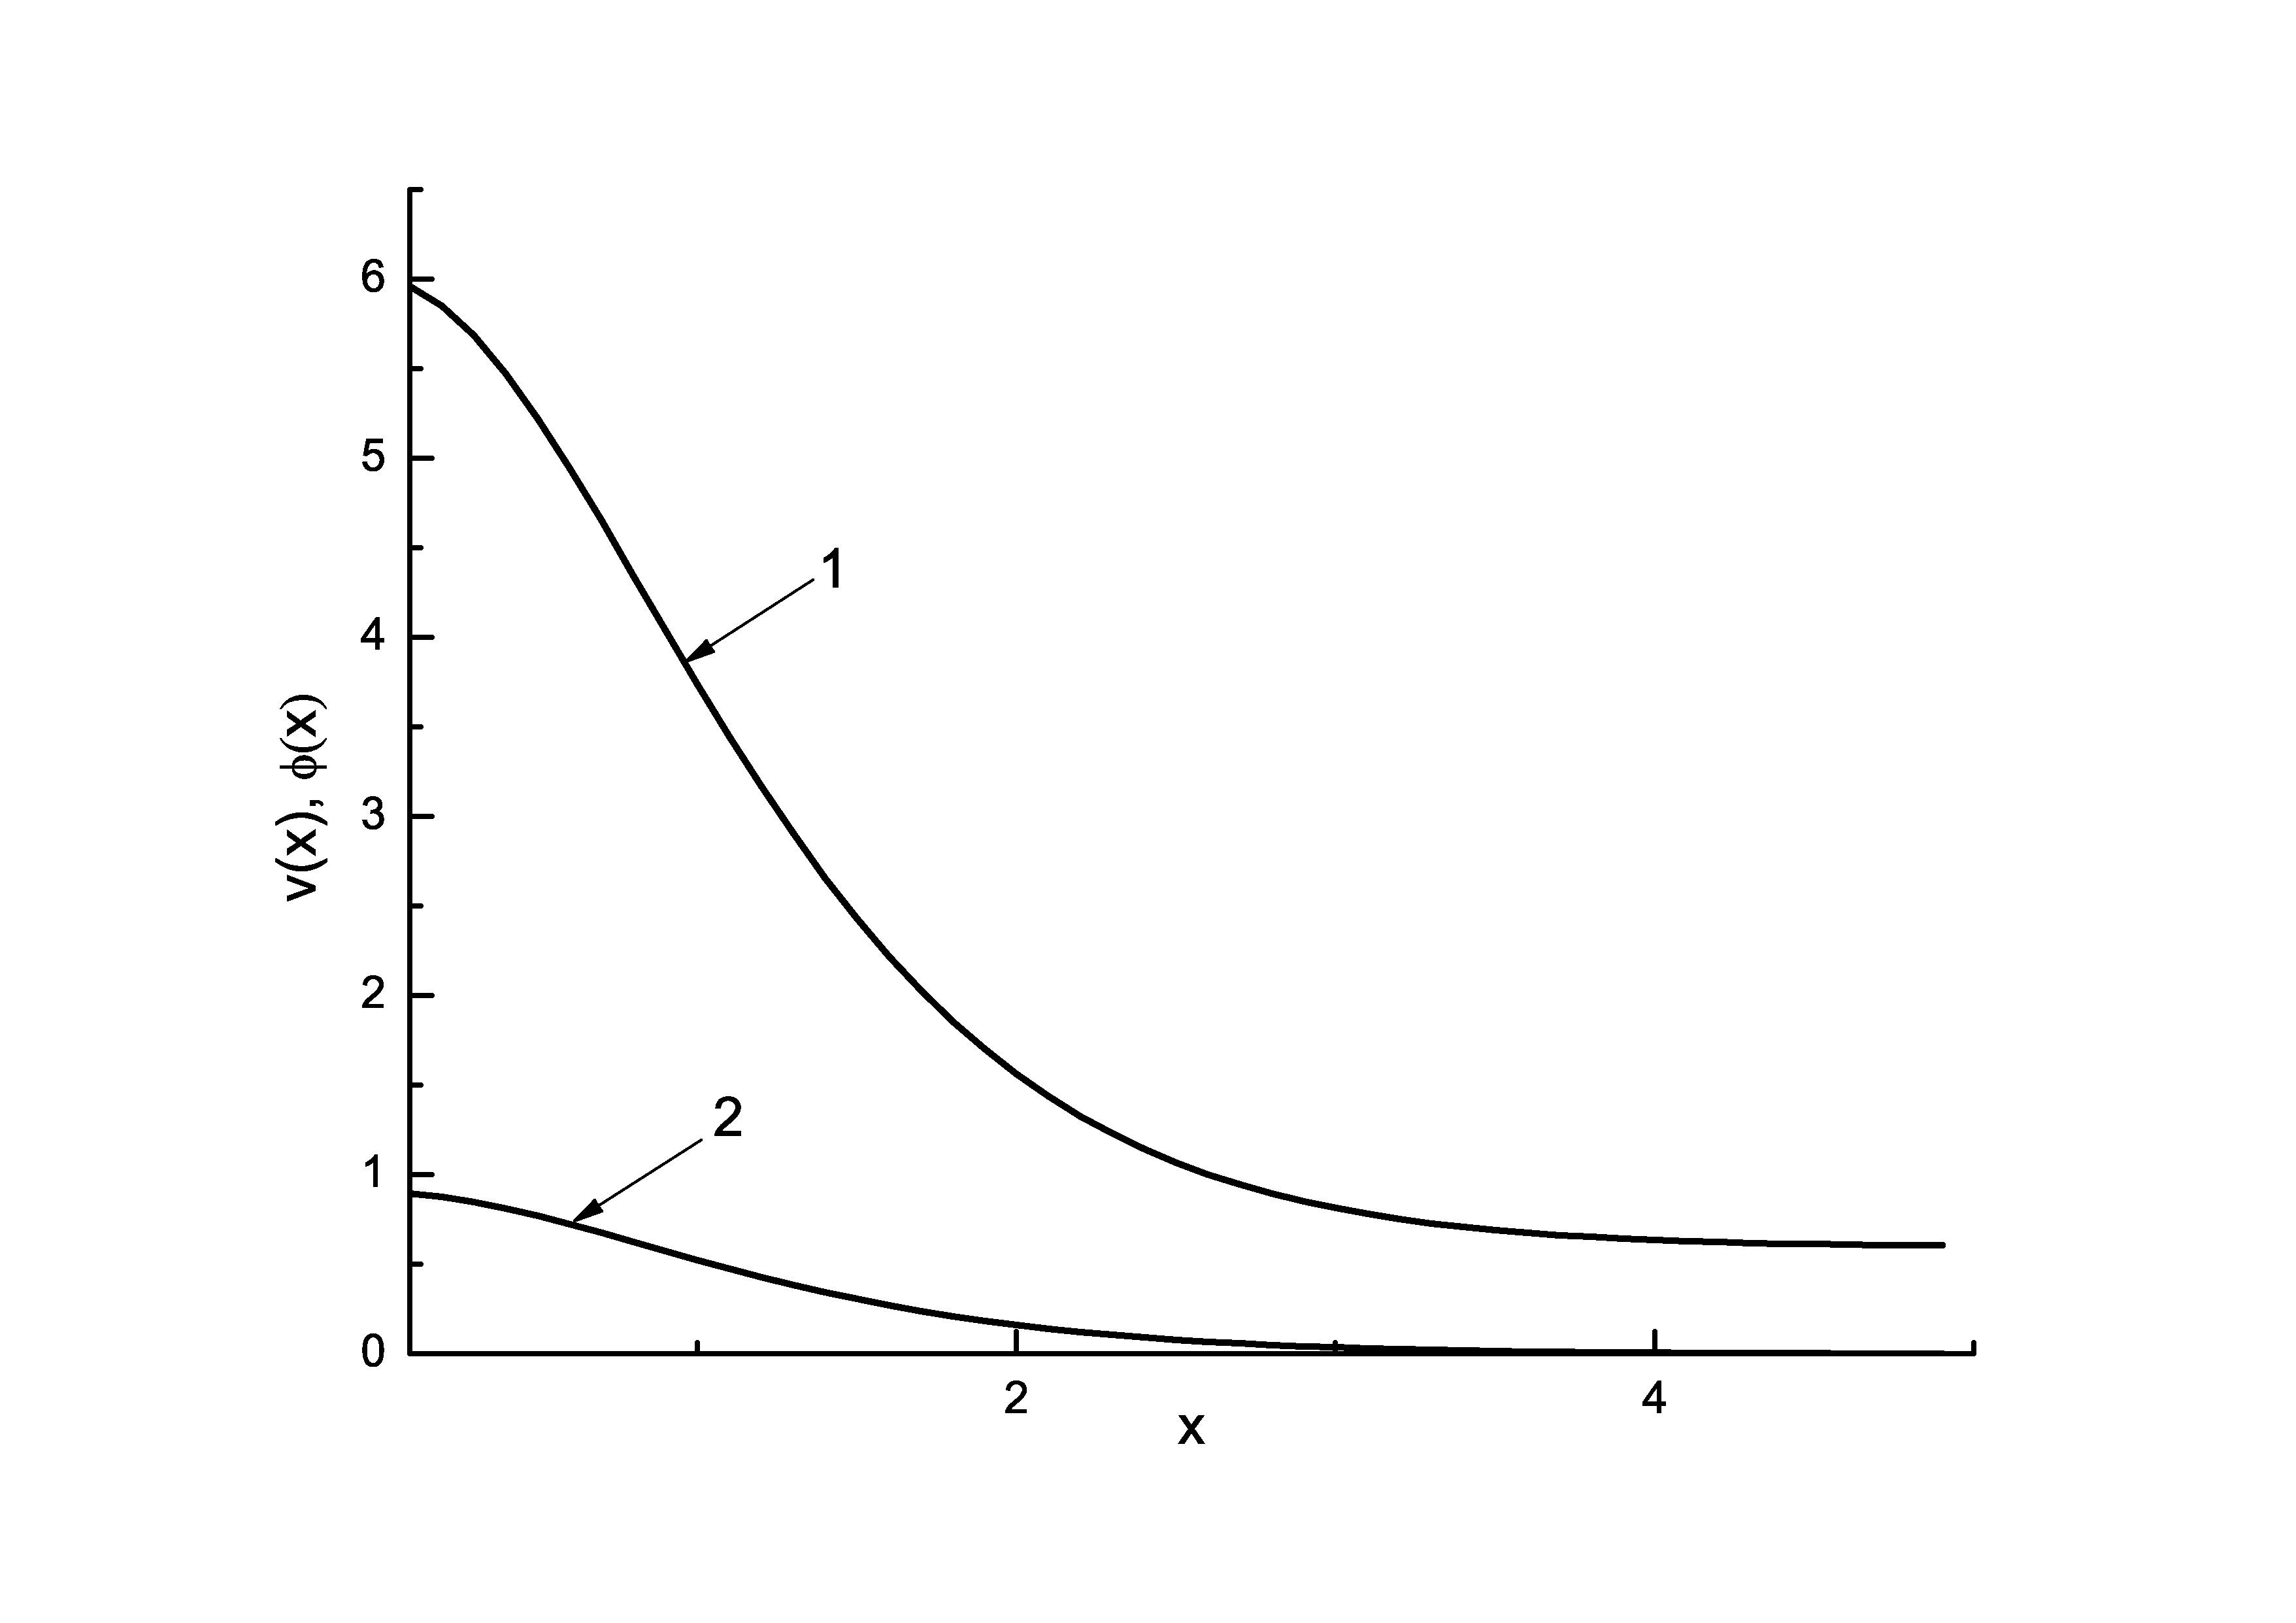

In [20]:
figure_dir = FIGURE_DIR

image_files = []
for ext in ("*.png", "*.jpg", "*.jpeg"):
    image_files.extend(sorted(glob.glob(os.path.join(figure_dir, "**", ext), recursive=True)))

if not image_files:
    print(f"No figures found in '{figure_dir}'.")
for img_path in image_files:
    print(img_path)
    display(Image(filename=img_path, width=400))


## 15. Final structured LLM analysis (OpenRouter) — selected source(s)

In [21]:
result_pdf = None
result_latex = None

for label, enriched_text in [("PDF", enriched_text_pdf), ("LaTeX", enriched_text_latex)]:
    if not enriched_text:
        continue
    model_name, raw_json = analyze_with_openrouter(enriched_text)
    try:
        result = json.loads(raw_json)
    except json.JSONDecodeError:
        print(f"[!] The {label} output is not valid JSON. Raw response:")
        print(raw_json)
        continue
    print(f"\n--- Result from {label} (model: {model_name}) ---")
    print(json.dumps(result, indent=2, ensure_ascii=False))
    if label == "PDF":
        result_pdf = result
    else:
        result_latex = result


[~] Sending paper content to OpenRouter (openrouter/free alias)...

--- Result from PDF (model: nvidia/nemotron-3-super-120b-a12b:free) ---
{
  "problem_addressed": "Connecting turbulence in fluid dynamics to flux tube formation in quantum chromodynamics via analogy between Reynolds number and coupling constant, aiming to understand quark confinement through turbulent flow models.",
  "main_contributions": [
    "Proposed analogy between Reynolds number (hydrodynamics) and dimensionless coupling constant (QCD) linking laminar/turbulent flow to perturbative/nonperturbative regimes.",
    "Derived a cylindrically symmetric turbulent flux tube solution using a one-function approximation for correlation functions, showing a core velocity profile and fluctuation profile.",
    "Demonstrated that similar assumptions in SU(3) gauge theory yield a flux tube with a nonzero chromoelectric field, analogous to the turbulent flux tube."
  ],
  "methodology": "Used statistical averaging of Navier-St

## 16. Grounded attribution (for both sources)

The pipeline's distinguishing point: the results stated by the authors and the formulas discovered by the visuo-mathematical analysis stay in two separate fields, without the LLM mixing them up — for both the PDF and the LaTeX analysis.

In [22]:
for label, result in [("PDF", result_pdf), ("LATEX", result_latex)]:
    if result is None:
        continue
    print(f"\n{'=' * 25} {label} {'=' * 25}")
    print("RESULTS STATED BY THE PAPER:\n")
    print(result.get("results", "Not specified"))
    print("\nAI APPROXIMATIONS FROM THE CHARTS (separate, not attributed to the authors):\n")
    for finding in result.get("visual_analysis_findings", []):
        print(f" - {finding}")



========================= PDF =========================
RESULTS STATED BY THE PAPER:

Obtained a turbulent flux tube solution with a core velocity profile v(x) (curve 1) and fluctuation profile φ(x) (curve 2) where velocity tends to zero at infinity, recovering laminar flow; found a QCD flux tube solution with nonzero longitudinal color electric field E_z^3 and flux Φ_E = 2π ∫0^∞ f v ρ dρ ≠ 0, analogous to the turbulent fluid flux; the solutions exist for negative parameters α, β and require α̃, β̃ < 0.

AI APPROXIMATIONS FROM THE CHARTS (separate, not attributed to the authors):


========================= LATEX =========================
RESULTS STATED BY THE PAPER:

Key results include the regime correspondence $\hbar \leftrightarrow \mu l^3$ and $1/\tilde g^2 \leftrightarrow \rho v^2 l^4$ linking laminar/perturbative to turbulent/nonperturbative regimes; numerically obtained velocity and fluctuation profiles in turbulent flow (Fig. 1); a regular cylindrically symmetric QCD flux tub

## 17. Direct comparison: PDF vs LaTeX, field by field

Only available with `TYPE = "both"`. A side-by-side print of every field of the JSON schema for the two sources, to see right away where the analysis matches and where it changes depending on the starting text (PDF extracted via PyMuPDF vs raw LaTeX source).

In [23]:
FIELDS = [
    "problem_addressed", "main_contributions", "methodology", "datasets_used",
    "experiments", "results", "limitations", "future_work",
    "relevant_elements", "visual_analysis_findings",
]

if result_pdf is not None and result_latex is not None:
    print("=" * 70)
    print(f"ANALYSIS COMPARISON: PDF vs LATEX -- paper: {os.path.basename(PDF_PATH)}")
    print("=" * 70)
    for field in FIELDS:
        print(f"\n--- {field} ---")
        print(f"[PDF]   {result_pdf.get(field)}")
        print(f"[LATEX] {result_latex.get(field)}")
else:
    print(f"Comparison skipped: it needs TYPE='both' and both analyses to succeed (current TYPE='{TYPE}').")


ANALYSIS COMPARISON: PDF vs LATEX -- paper: 1482468_Flux tube in turbulent flow and quantum chromodyna.pdf

--- problem_addressed ---
[PDF]   Connecting turbulence in fluid dynamics to flux tube formation in quantum chromodynamics via analogy between Reynolds number and coupling constant, aiming to understand quark confinement through turbulent flow models.
[LATEX] The paper addresses the connection between turbulence in fluid dynamics and nonperturbative quantum chromodynamics (QCD), aiming to establish analogies between turbulent flow structures and QCD flux tubes, particularly in the context of quark confinement and the nonperturbative quantization problem.

--- main_contributions ---
[PDF]   ['Proposed analogy between Reynolds number (hydrodynamics) and dimensionless coupling constant (QCD) linking laminar/turbulent flow to perturbative/nonperturbative regimes.', 'Derived a cylindrically symmetric turbulent flux tube solution using a one-function approximation for correlation funct